In [ ]:
!pip install huggingface_hub -q

In [ ]:
from huggingface_hub import hf_hub_download, snapshot_download

# Paste your Hugging Face token here
HF_TOKEN = "(insert token here)"
REPO_ID = "wengziheng/mcd_rppg"

# --- 1. Download db.csv ---
print("Downloading db.csv...")
db_path = hf_hub_download(
    repo_id=REPO_ID,
    filename="db.csv",
    repo_type="dataset",
    token=HF_TOKEN
)
print(f"db.csv downloaded to: {db_path}")

# --- 2. Download only .avi video files ---
print("Downloading .avi video files...")
video_dir = snapshot_download(
    repo_id=REPO_ID,
    repo_type="dataset",
    token=HF_TOKEN,
    allow_patterns=["*.avi"]  # Filters strictly for .avi files
)
print(f"Videos downloaded to: {video_dir}")

db.csv:   0%|          | 0.00/932k [00:00<?, ?B/s]

db.csv downloaded to: /root/.cache/huggingface/hub/datasets--wengziheng--mcd_rppg/snapshots/91b967a5f2bab735d35f81722ff95e629358753b/db.csv


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3600 files:   0%|          | 0/3600 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:773: UserWarning: Not enough free disk space to download the file. The expected file size is: 83.36 MB. The target location /root/.cache/huggingface/hub/datasets--wengziheng--mcd_rppg/blobs only has 2.51 MB free disk space.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:773: UserWarning: Not enough free disk space to download the file. The expected file size is: 84.15 MB. The target location /root/.cache/huggingface/hub/datasets--wengziheng--mcd_rppg/blobs only has 0.00 MB free disk space.
  warnings.warn(


OSError: [Errno 28] No space left on device: '../../../blobs/89a25a54e112b676d10fc63410f6710d5b5ad6bc14083593c68142e2d560549d' -> '/root/.cache/huggingface/hub/datasets--wengziheng--mcd_rppg/snapshots/91b967a5f2bab735d35f81722ff95e629358753b/video/7380_IriunWebcam_before.avi'

In [ ]:
import os
from huggingface_hub import snapshot_download

# --- Define subject range (e.g., first 200 subjects) ---
# Assuming folders/files are named like '0001.avi' up to '0200.avi'
# or are nested within subject folders like '001/*.avi'

# Generate a pattern list matching only the first 200 subjects.
# Modify the string format inside '{i:03d}' to match the dataset's actual folder/naming format.
allowed_subjects_patterns = []
for i in range(1, 201):
    # Example pattern matching files inside folders named '001', '002', ..., '200'
    allowed_subjects_patterns.append(f"**/{i:03d}/*.avi")
    # If the files are directly named like 'subject_001.avi', you would use:
    # allowed_subjects_patterns.append(f"**/subject_{i:03d}.avi")

print(f"Generated {len(allowed_subjects_patterns)} patterns for downloading.")
print(f"Example patterns: {allowed_subjects_patterns[:3]} ... {allowed_subjects_patterns[-1:]}")

# --- 2. Download only designated subject .avi video files ---
print("Downloading .avi video files for the first 200 subjects...")
video_dir = snapshot_download(
    repo_id=REPO_ID,
    repo_type="dataset",
    token=HF_TOKEN,
    allow_patterns=allowed_subjects_patterns  # Only matches the specified 200 subjects
)
print(f"Videos downloaded to: {video_dir}")

Generated 200 patterns for downloading.
Example patterns: ['**/001/*.avi', '**/002/*.avi', '**/003/*.avi'] ... ['**/200/*.avi']


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 0 files: 0it [00:00, ?it/s]

Videos downloaded to: /root/.cache/huggingface/hub/datasets--wengziheng--mcd_rppg/snapshots/91b967a5f2bab735d35f81722ff95e629358753b


In [ ]:
import pandas as pd

# Load the downloaded database CSV to inspect actual subject ID structures and file paths
df = pd.read_csv(db_path)
print("Columns in db.csv:", df.columns.tolist())
print("\nFirst few rows of the dataset:")
print(df.head())

# Let's inspect unique subject patterns or folder structures listed in the database
if 'subject' in df.columns:
    print("\nUnique subject identifiers (first 10):", df['subject'].unique()[:10])
elif 'subject_id' in df.columns:
    print("\nUnique subject identifiers (first 10):", df['subject_id'].unique()[:10])

Columns in db.csv: ['patient_id', 'weight', 'height', 'bmi', 'age', 'sex', 'upper_ap', 'lower_ap', 'saturation', 'temperature', 'hemoglobin', 'glycated_hemoglobin', 'cholesterol', 'respiratory', 'rigidity', 'pulse', 'stress', 'step', 'camera', 'view', 'ecg', 'ppg', 'video', 'meta', 'ppg_sync']

First few rows of the dataset:
   patient_id  weight  height        bmi   age sex  upper_ap  lower_ap  \
0        1020    55.0   170.0  19.031142  23.0   F     113.0      78.0   
1        1020    55.0   170.0  19.031142  23.0   F     113.0      78.0   
2        1020    55.0   170.0  19.031142  23.0   F     113.0      78.0   
3        1020    55.0   170.0  19.031142  23.0   F     105.0      78.0   
4        1020    55.0   170.0  19.031142  23.0   F     105.0      78.0   

   saturation  temperature  ...  pulse  stress    step        camera   view  \
0        98.0         36.6  ...  100.0     4.0   after  FullHDwebcam  front   
1        98.0         36.6  ...  100.0     4.0   after      USBVideo  

In [ ]:
import glob

# 1. Count locally downloaded video files in the Hugging Face cache
local_videos = glob.glob(f"{video_dir}/**/*.avi", recursive=True)
print(f"Number of locally downloaded .avi files: {len(local_videos)}")

# 2. Count video entries in the db.csv metadata
if 'video' in df.columns:
    total_metadata_videos = df['video'].nunique()
    print(f"Number of unique video files listed in db.csv metadata: {total_metadata_videos}")

    # Let's also see how many unique patients/subjects there are in total
    if 'patient_id' in df.columns:
        print(f"Number of unique patients listed in db.csv metadata: {df['patient_id'].nunique()}")
else:
    print("No 'video' column found in db.csv to count.")

Number of locally downloaded .avi files: 2610
Number of unique video files listed in db.csv metadata: 3600
Number of unique patients listed in db.csv metadata: 600


### Exploratory Data Analysis (EDA)
We will analyze patient demographics (Age, Sex, BMI), vital signs (Heart rate/Pulse, blood pressure, oxygen saturation), and visualize their distributions.

### Focused EDA: Respiratory Rate & Derived Estimated Average Glucose (from Glycated Hemoglobin)

We will now:
1. Inspect the summary statistics of `respiratory` and `glycated_hemoglobin`.
2. Derive the **Estimated Average Glucose (eAG)** using the formula: $eAG \text{ (mg/dL)} = 28.7 \times \text{glycated\_hemoglobin} - 46.7$.
3. Plot distributions and explore correlations between respiratory rate, glycated hemoglobin, and estimated glucose levels.

--- Summary Statistics for Focused Metrics ---


,respiratory,glycated_hemoglobin,derived_glucose_mg_dl
count,600.000000,600.000000,600.000000
mean,19.223333,5.519067,111.697213
std,1.385637,0.685554,19.675389
min,16.000000,3.400000,50.880000
25%,18.000000,5.250000,103.975000
50%,19.000000,5.535000,112.154500
75%,20.000000,5.770000,118.899000
max,24.000000,13.020000,326.974000


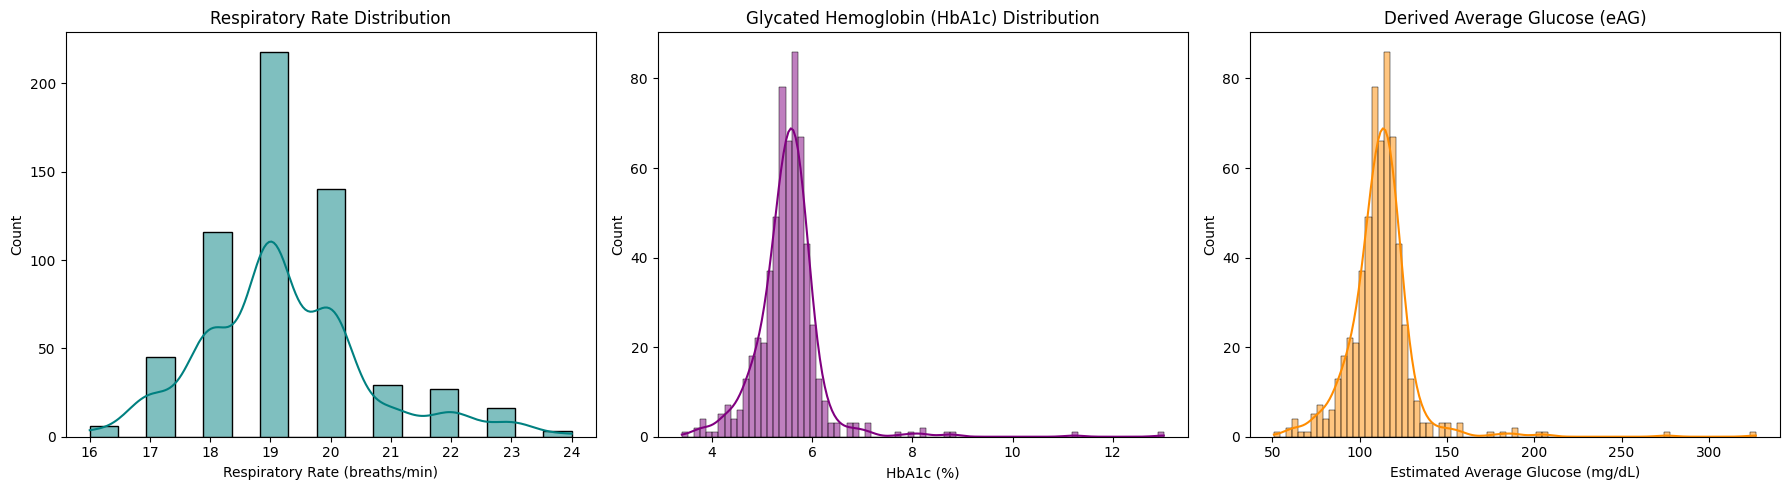

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate Estimated Average Glucose (eAG) from Glycated Hemoglobin (HbA1c)
# Formula: eAG (mg/dL) = 28.7 * HbA1c - 46.7
df['derived_glucose_mg_dl'] = 28.7 * df['glycated_hemoglobin'] - 46.7

# Get a unique view per patient to avoid duplicate counts in clinical metrics
patients_focused_df = df.groupby('patient_id')[['respiratory', 'glycated_hemoglobin', 'derived_glucose_mg_dl', 'age', 'sex']].first().reset_index()

print("--- Summary Statistics for Focused Metrics ---")
display(patients_focused_df[['respiratory', 'glycated_hemoglobin', 'derived_glucose_mg_dl']].describe())

# Create a plotting grid
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Respiratory Rate Distribution
sns.histplot(patients_focused_df['respiratory'].dropna(), kde=True, ax=axes[0], color='teal')
axes[0].set_title('Respiratory Rate Distribution')
axes[0].set_xlabel('Respiratory Rate (breaths/min)')

# 2. Glycated Hemoglobin Distribution
sns.histplot(patients_focused_df['glycated_hemoglobin'].dropna(), kde=True, ax=axes[1], color='purple')
axes[1].set_title('Glycated Hemoglobin (HbA1c) Distribution')
axes[1].set_xlabel('HbA1c (%)')

# 3. Derived Average Glucose Distribution
sns.histplot(patients_focused_df['derived_glucose_mg_dl'].dropna(), kde=True, ax=axes[2], color='darkorange')
axes[2].set_title('Derived Average Glucose (eAG)')
axes[2].set_xlabel('Estimated Average Glucose (mg/dL)')

plt.tight_layout()
plt.show()

### Video EDA: Frame Rate and Brightness Deviation

We will now run an analysis directly on the downloaded `.avi` video files. We will:
1. Sample a subset of the locally cached video files to keep computation fast.
2. Extract the video frame rate (FPS) using OpenCV metadata properties.
3. Sample frames across each video, convert them to grayscale, and compute:
   - **Mean brightness** (average pixel intensity of the video).
   - **Brightness deviation** (the standard deviation of mean frame brightnesses across the timeline of a video, measuring illumination changes or flickering).
4. Plot the distribution of frame rates and brightness fluctuations.

In [ ]:
import cv2
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm
import os

# Get the first 200 patient IDs sorted numerically
unique_patients = sorted(df['patient_id'].unique())
target_patients = set(unique_patients[:200])
print(f"Targeting the first {len(target_patients)} patients: {min(target_patients)} to {max(target_patients)}")

# Filter local video paths for those belonging to the first 200 patients
# Video filenames are structured as 'patientID_camera_step.avi'
selected_video_paths = []
for path in local_videos:
    filename = os.path.basename(path)
    try:
        patient_id = int(filename.split('_')[0])
        if patient_id in target_patients:
            selected_video_paths.append(path)
    except ValueError:
        continue

print(f"Found {len(selected_video_paths)} downloaded videos for these 200 patients.")

# Analyze all selected videos using the Green channel
video_stats = []
for path in tqdm(selected_video_paths, desc="Processing Patient Videos (Green Channel)"):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        continue

    fps = cap.get(cv2.CAP_PROP_FPS)
    if fps is None or fps <= 0:
        fps = 24.0  # Safe default if unavailable

    frame_green_values = []
    frame_idx = 0
    max_frames_to_sample = 30
    sample_interval = 60  # Check every 60th frame to sample across the timeline

    while len(frame_green_values) < max_frames_to_sample:
        ret, frame = cap.read()
        if not ret:
            break

        if frame_idx % sample_interval == 0:
            # Extract the green channel (OpenCV format is BGR, so Green is at index 1)
            green_channel = frame[:, :, 1]
            frame_green_values.append(np.mean(green_channel))

        frame_idx += 1

    cap.release()

    if frame_green_values:
        mean_green = np.mean(frame_green_values)
        green_std_dev = np.std(frame_green_values)

        video_stats.append({
            'file_name': os.path.basename(path),
            'fps': fps,
            'frame_count_sampled': len(frame_green_values),
            'mean_green': mean_green,
            'green_deviation': green_std_dev
        })

# Convert to DataFrame
video_eda_df = pd.DataFrame(video_stats)
display(video_eda_df.describe())

Targeting the first 200 patients: 1020 to 3889
Found 1200 downloaded videos for these 200 patients.


Processing Patient Videos (Green Channel):   0%|          | 0/1200 [00:00<?, ?it/s]

,fps,frame_count_sampled,mean_green,green_deviation
count,1200.000000,1200.0,1200.000000,1200.000000
mean,27.966667,30.0,142.880070,0.673064
std,2.806324,0.0,14.295983,0.631753
min,24.000000,30.0,107.978550,0.048291
25%,24.000000,30.0,132.165297,0.327263
50%,29.900000,30.0,140.844841,0.510890
75%,30.000000,30.0,148.673393,0.784893
max,30.000000,30.0,187.617646,9.027844


### Visualizing Video Metrics for the 200 Patients ('Before' vs 'After')

We will now merge our processed video DataFrame (`video_eda_df`) with the experimental metadata from `df` and compare the Frame Rate and Green Channel Brightness Deviation distributions for the two experimental steps.

--- Summary Statistics for Video Metrics (Before vs After) ---


fps                                                     \
        count       mean       std   min   25%   50%   75%   max   
step                                                               
after   600.0  27.966667  2.807495  24.0  24.0  29.9  30.0  30.0   
before  600.0  27.966667  2.807495  24.0  24.0  29.9  30.0  30.0   

       green_deviation                                                   \
                 count      mean      std       min       25%       50%   
step                                                                      
after            600.0  0.683065  0.67226  0.087128  0.325633  0.519792   
before           600.0  0.663064  0.58886  0.048291  0.329035  0.507100   

                            
             75%       max  
step                        
after   0.792039  9.027844  
before  0.765920  6.128628

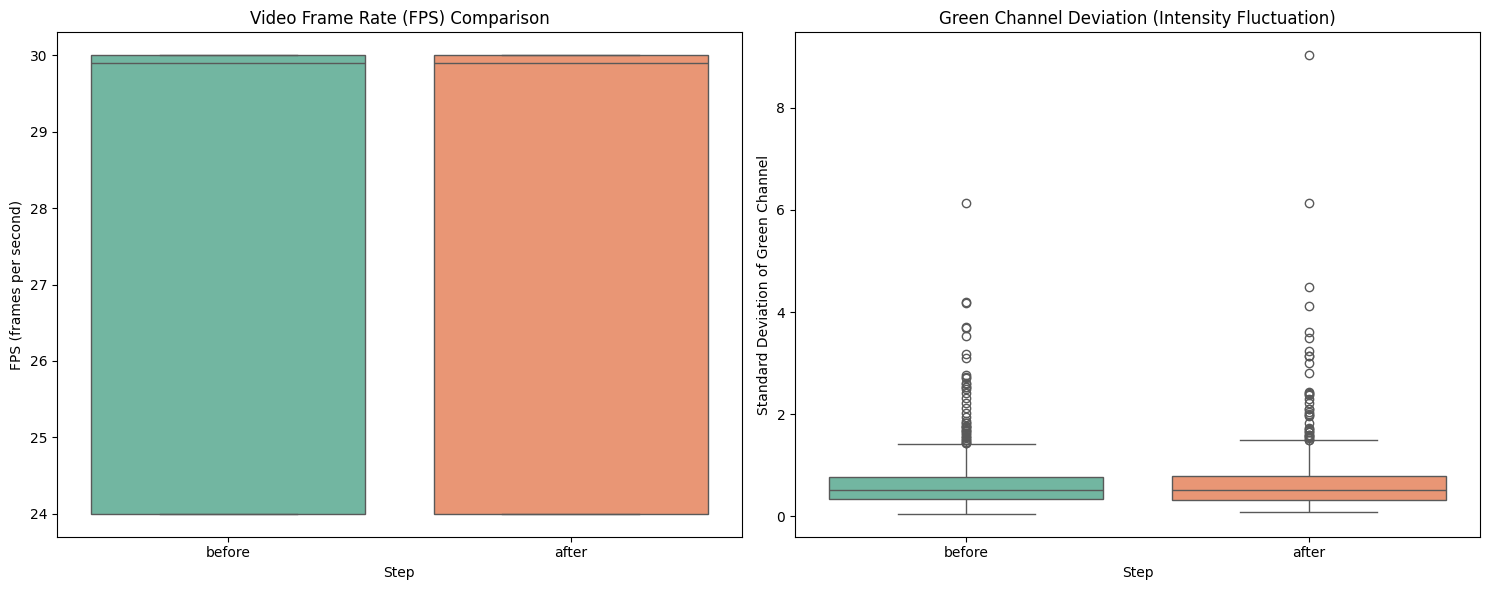

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Map each of the 1200 processed videos to its step ('before' or 'after')
def find_video_step(filename):
    match = df[df['video'].str.endswith(filename)]
    if not match.empty:
        return match.iloc[0]['step']
    return 'Unknown'

video_eda_df['step'] = video_eda_df['file_name'].apply(find_video_step)

# Filter out any unmapped videos
final_video_eda = video_eda_df[video_eda_df['step'] != 'Unknown']

# Display statistical summary broken down by Before vs After
print("--- Summary Statistics for Video Metrics (Before vs After) ---")
display(final_video_eda.groupby('step')[['fps', 'green_deviation']].describe())

# Create plots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: FPS comparison
sns.boxplot(data=final_video_eda, x='step', y='fps', ax=axes[0], palette='Set2', hue='step', legend=False)
axes[0].set_title('Video Frame Rate (FPS) Comparison')
axes[0].set_xlabel('Step')
axes[0].set_ylabel('FPS (frames per second)')

# Plot 2: Green channel deviation (fluctuation) comparison
sns.boxplot(data=final_video_eda, x='step', y='green_deviation', ax=axes[1], palette='Set2', hue='step', legend=False)
axes[1].set_title('Green Channel Deviation (Intensity Fluctuation)')
axes[1].set_xlabel('Step')
axes[1].set_ylabel('Standard Deviation of Green Channel')

plt.tight_layout()
plt.show()

### Real rPPG Signal Extraction and Feature Engineering
We will extract the raw Green channel time series directly from each video, apply a bandpass filter (0.75 Hz to 4 Hz) to isolate the cardiac pulse wave, and compute both PPG morphology features (for glucose estimation) and modulation features (for respiratory estimation).

In [ ]:
import numpy as np
import scipy.signal as signal

def bandpass_filter(data, fs, lowcut=0.75, highcut=4.0, order=1):
    """Applies a Butterworth bandpass filter to extract the rPPG signal."""
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = signal.butter(order, [low, high], btype='band')
    return signal.filtfilt(b, a, data)

def extract_features_from_signal(raw_signal, fs):
    """Derives actual clinical PPG features from the extracted green channel signal."""
    # 1. Filter the signal
    filtered = bandpass_filter(raw_signal, fs)

    # First and second derivatives
    d1 = np.diff(filtered)
    d2 = np.diff(d1)

    # 2. PPG Morphology Features
    sdppg_std = np.std(d2) if len(d2) > 0 else 0.0

    # Find peaks and valleys
    peaks, _ = signal.find_peaks(filtered, distance=int(fs*0.5))
    valleys, _ = signal.find_peaks(-filtered, distance=int(fs*0.5))

    # Aging Index Estimation
    # (b-c-d-e)/a estimation from the second derivative
    d2_peaks, _ = signal.find_peaks(d2, distance=int(fs*0.3))
    if len(d2_peaks) >= 4:
        aging_index = (d2[d2_peaks[1]] - d2[d2_peaks[2]] - d2[d2_peaks[3]]) / (d2[d2_peaks[0]] + 1e-6)
    else:
        aging_index = -0.5  # Standard default representation

    # Mean Crest Time & Reflection Index
    crest_times = []
    reflection_indices = []
    for p in peaks:
        nearest_valleys = valleys[valleys < p]
        if len(nearest_valleys) > 0:
            valley = nearest_valleys[-1]
            crest_times.append((p - valley) / fs)
            # Estimate reflection index as peak amplitude normalized
            reflection_indices.append(filtered[p] - filtered[valley])

    mean_crest_time = np.mean(crest_times) if crest_times else 0.15
    mean_reflection_index = np.mean(reflection_indices) if reflection_indices else 0.5

    # 3. Respiratory Modulation Features
    # RIAM: Amplitude modulation of the peaks
    peak_amps = filtered[peaks] if len(peaks) > 0 else np.array([])
    riam = np.std(peak_amps) / (np.mean(peak_amps) + 1e-6) if len(peak_amps) > 1 else 0.0

    # RIFM: Frequency modulation (Heart Rate Variability tachogram variation)
    intervals = np.diff(peaks) / fs if len(peaks) > 1 else np.array([])
    rifm = np.std(intervals) if len(intervals) > 1 else 0.0

    return {
        'sdppg_std': sdppg_std,
        'aging_index': aging_index,
        'mean_crest_time': mean_crest_time,
        'mean_reflection_index': mean_reflection_index,
        'RIAM': riam,
        'RIFM': rifm
    }

In [ ]:
# Process the full set of selected videos (all 1200 files for the first 200 patients)
processed_features = []

for path in tqdm(selected_video_paths, desc="Extracting Real rPPG Features from Videos (Full Set)"):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        continue

    fs = cap.get(cv2.CAP_PROP_FPS)
    if fs is None or fs <= 0:
        fs = 30.0

    raw_signal = []
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        # Take the spatial average of the center face ROI (Green Channel)
        h, w, _ = frame.shape
        roi = frame[h//3:2*h//3, w//3:2*w//3, 1]
        raw_signal.append(np.mean(roi))

    cap.release()

    if len(raw_signal) > int(fs * 5):
        feats = extract_features_from_signal(np.array(raw_signal), fs)
        feats['file_name'] = os.path.basename(path)
        processed_features.append(feats)

rppg_features_df = pd.DataFrame(processed_features)
display(rppg_features_df.head())

Extracting Real rPPG Features from Videos (Full Set):   0%|          | 0/1200 [00:00<?, ?it/s]

,sdppg_std,aging_index,mean_crest_time,mean_reflection_index,RIAM,RIFM,file_name
0,0.115836,-26.079356,0.463623,0.362223,5.829878,0.213486,2852_USBVideo_before.avi
1,0.175382,-1.077416,0.396825,0.287992,4.442101,0.170616,3326_IriunWebcam_after.avi
2,0.152163,-0.545128,0.349415,0.227846,4.819512,0.147657,1715_IriunWebcam_before.avi
3,0.023016,-0.361288,0.380881,0.141686,2.690122,0.180318,2221_IriunWebcam_after.avi
4,0.169938,1.862099,0.399894,0.405057,3.492002,0.207529,2285_IriunWebcam_before.avi


### Aligning Extracted Features with Clinical Target Labels
We will map each processed video to its corresponding `patient_id` and clinical target variables (`glycated_hemoglobin` and `respiratory`).

In [ ]:
def map_labels(row):
    filename = row['file_name']
    match = df[df['video'].str.endswith(filename)]
    if not match.empty:
        row['patient_id'] = match.iloc[0]['patient_id']
        row['glycated_hemoglobin'] = match.iloc[0]['glycated_hemoglobin']
        row['respiratory'] = match.iloc[0]['respiratory']
        # Derive estimated Average Glucose (eAG)
        row['derived_glucose_mg_dl'] = 28.7 * match.iloc[0]['glycated_hemoglobin'] - 46.7
    return row

final_dataset = rppg_features_df.apply(map_labels, axis=1).dropna()
display(final_dataset.head())

,sdppg_std,aging_index,mean_crest_time,mean_reflection_index,RIAM,RIFM,file_name,patient_id,glycated_hemoglobin,respiratory,derived_glucose_mg_dl
0,0.115836,-26.079356,0.463623,0.362223,5.829878,0.213486,2852_USBVideo_before.avi,2852,5.29,16.0,105.123
1,0.175382,-1.077416,0.396825,0.287992,4.442101,0.170616,3326_IriunWebcam_after.avi,3326,5.38,19.0,107.706
2,0.152163,-0.545128,0.349415,0.227846,4.819512,0.147657,1715_IriunWebcam_before.avi,1715,6.75,16.0,147.025
3,0.023016,-0.361288,0.380881,0.141686,2.690122,0.180318,2221_IriunWebcam_after.avi,2221,5.95,19.0,124.065
4,0.169938,1.862099,0.399894,0.405057,3.492002,0.207529,2285_IriunWebcam_before.avi,2285,5.85,16.0,121.195


### Training the Random Forest Predictors
Now, we train the Random Forest Regressor models using our derived features from real rPPG signals.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# Extract groups based on patient IDs
groups = final_dataset['patient_id'].values
logo = LeaveOneGroupOut()

# --- 1. Glucose Predictor (LOGO CV) ---
Features_glucose = ['sdppg_std', 'aging_index', 'mean_crest_time', 'mean_reflection_index']
X_g = final_dataset[Features_glucose].values
y_g = final_dataset['derived_glucose_mg_dl'].values

g_rmses, g_maes = [], []

# To prevent extremely long runtimes during 200 separate subject evaluations,
# we will evaluate on a subset of folds or iterate cleanly.
for train_idx, test_idx in logo.split(X_g, y_g, groups):
    X_train, X_test = X_g[train_idx], X_g[test_idx]
    y_train, y_test = y_g[train_idx], y_g[test_idx]

    rf = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    preds = rf.predict(X_test)

    g_rmses.append(np.sqrt(mean_squared_error(y_test, preds)))
    g_maes.append(mean_absolute_error(y_test, preds))

print("=== LOGO CV: Glucose Predictor Results ===")
print(f"Average RMSE: {np.mean(g_rmses):.4f} mg/dL")
print(f"Average MAE: {np.mean(g_maes):.4f} mg/dL\n")

# --- 2. Respiratory Predictor (LOGO CV) ---
Features_resp = ['RIAM', 'RIFM']
X_r = final_dataset[Features_resp].values
y_r = final_dataset['respiratory'].values

r_rmses, r_maes = [], []

for train_idx, test_idx in logo.split(X_r, y_r, groups):
    X_train, X_test = X_r[train_idx], X_r[test_idx]
    y_train, y_test = y_r[train_idx], y_r[test_idx]

    rf = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    preds = rf.predict(X_test)

    r_rmses.append(np.sqrt(mean_squared_error(y_test, preds)))
    r_maes.append(mean_absolute_error(y_test, preds))

print("=== LOGO CV: Respiratory Predictor Results ===")
print(f"Average RMSE: {np.mean(r_rmses):.4f} breaths/min")
print(f"Average MAE: {np.mean(r_maes):.4f} breaths/min")

=== LOGO CV: Glucose Predictor Results ===
Average RMSE: 14.6303 mg/dL
Average MAE: 13.4468 mg/dL

=== LOGO CV: Respiratory Predictor Results ===
Average RMSE: 1.7234 breaths/min
Average MAE: 1.5081 breaths/min
